# Split Decision: critics and audiences

Do critics and audiences give similar approval scores to the same movies? I compare the overall gaps, look at genres, and check whether different review-count rules and release-period mixes change the results. The app is for movie fans who want to look beyond one headline score.

I use the movie table from [Stefano Leone’s Rotten Tomatoes dataset](https://www.kaggle.com/datasets/stefanoleone992/rotten-tomatoes-movies-and-critic-reviews-dataset): 17,712 titles and 22 columns, collected through October 31, 2020. Each Rotten Tomatoes link identifies a title. The source includes some TV and non-theatrical entries and is listed as CC0. The separate critic-review text is not needed for these comparisons.

In [1]:
from pathlib import Path
import sys
import altair as alt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "analysis.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "analysis.py").exists(), "Open this notebook from the project or notebooks folder."
sys.path.insert(0, str(ROOT))
from analysis import (
    GROUPS,
    SCORES,
    PROFILES,
    compare_profiles,
    comparison_chart,
    filter_movies,
    genre_chart,
    genre_summary,
    load_movies,
    load_prepared,
    period_chart,
    period_genres,
    period_summary,
    score_chart,
    standardized_genres,
    summary,
)
from scripts.check_project import audit

alt.data_transformers.disable_max_rows()
alt.renderers.enable("png")
raw, movies = load_movies()
print(f"{len(raw):,} rows × {len(raw.columns)} columns")
raw[
    [
        "rotten_tomatoes_link",
        "movie_title",
        "genres",
        "tomatometer_rating",
        "audience_rating",
        "tomatometer_count",
        "audience_count",
        "original_release_date",
    ]
].head(3)


17,712 rows × 22 columns


,rotten_tomatoes_link,movie_title,genres,tomatometer_rating,audience_rating,tomatometer_count,audience_count,original_release_date
0,m/0814255,Percy Jackson & the Olympians: The Lightning T...,"Action & Adventure, Comedy, Drama, Science Fic...",49.0,53.0,149.0,254421.0,2010-02-12
1,m/0878835,Please Give,Comedy,87.0,64.0,142.0,11574.0,2010-04-30
2,m/10,10,"Comedy, Romance",67.0,53.0,24.0,14684.0,1979-10-05


## Variables used

These fields define the title, the two scores, and the groups used in the analysis.

| Variable | What it contains | How it is used |
|---|---|---|
| rotten_tomatoes_link | Title ID, text | Identify titles; names alone are not unique |
| movie_title | Title name, text | Label the results |
| tomatometer_rating | Critic approval, numeric, 0–100 | Compare scores; keep valid zeros |
| audience_rating | Audience approval, numeric, 0–100 | Compare scores; keep valid zeros |
| tomatometer_count | Critic review count, numeric | Set a minimum count, not a weight |
| audience_count | Audience rating count, numeric | Set a minimum count and check the wide range |
| genres | Genre labels, categorical text | Split labels for the genre comparison |
| original_release_date | Release date, stored as text | Extract the year for release-period comparisons |
| gap_pp | Calculated difference, numeric | Audience approval minus critic approval |
| absolute_gap_pp | Size of the difference, numeric | Compare gaps without their direction |

Gap = audience approval minus critic approval, in **percentage points**. For example, 80% minus 60% is 20 points. The processed table retains all source rows; filters choose which titles enter a comparison.

In [2]:
quality = audit(raw)
display(
    pd.Series(
        {key: value for key, value in quality.items() if not isinstance(value, dict)},
        name="value",
    ).to_frame()
)
display(
    pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum()}).assign(
        percent=lambda d: (100 * d.missing / len(raw)).round(2)
    )
)
display(
    raw[["tomatometer_count", "audience_count", "runtime"]]
    .describe(percentiles=[0.5, 0.9, 0.99]) .round(1))

print("Score range violations:", quality["scores_outside_0_100"])
print("Nonpositive counts:", quality["nonpositive_counts"])
print(
    "Unparseable observed release dates:",
    pd.to_datetime(raw.original_release_date.dropna(), errors="coerce").isna().sum(),
)


,value
rows,17712
columns,22
exact_duplicates,0
duplicate_ids,0
repeated_title_strings,606
critic_count_mismatches,279


,dtype,missing,percent
rotten_tomatoes_link,object,0,0.00
movie_title,object,0,0.00
movie_info,object,321,1.81
critics_consensus,object,8578,48.43
content_rating,object,0,0.00
genres,object,19,0.11
directors,object,194,1.10
authors,object,1542,8.71
actors,object,352,1.99
original_release_date,object,1166,6.58


,tomatometer_count,audience_count,runtime
count,17668.0,17415.0,17398.0
mean,57.1,143940.1,102.2
std,68.4,1763577.4,18.7
min,5.0,5.0,5.0
50%,28.0,4277.0,99.0
90%,155.0,125158.0,125.0
99%,308.0,877767.5,165.0
max,574.0,35797635.0,266.0


Score range violations: {'tomatometer_rating': 0, 'audience_rating': 0}
Nonpositive counts: {'tomatometer_count': 0, 'audience_count': 0}
Unparseable observed release dates: 0


## Cleaning decisions

There are no exact duplicate rows or repeated IDs. I keep the entries with repeated names because different titles can share a name.

Comparisons require both approval scores between 0 and 100 and both review counts. I leave missing scores and counts unfilled and retain valid zero scores. Missing genres affect genre grouping only. Missing release years affect period comparisons only.

The default minimums are **20 critic reviews and 100 audience ratings**. These are starting choices to avoid very small counts. Each title has equal weight, and unusually large review counts stay in the data.

For 279 titles, the fresh and rotten critic counts do not add up to the reported total. The publisher notes different collection times, so I use the published scores rather than reconstructing them. No merge is needed because the required fields are in one table.

In [3]:
paired = movies[SCORES].notna().all(axis=1)
base = filter_movies(movies)
display(
    pd.Series(
        {
            "source_titles": len(raw),
            "both_scores": int(paired.sum()),
            "both_scores_and_counts": len(filter_movies(movies, 0, 0)),
            "default_view": len(base),
        },
        name="titles",
    ).to_frame()
)
assert base.rotten_tomatoes_link.is_unique
assert len(base) == 10503


,titles
source_titles,17712
both_scores,17407
both_scores_and_counts,17406
default_view,10503


## Question 1: How often do critics and audiences disagree?

The plot groups scores into five-point ranges. Darker squares contain more titles, and the dashed line marks equal scores.

The table separates titles by whether each score reaches 60%. A 59%/60% pair crosses that line with only a one-point gap. I also measure the distance between scores and the share at least 20 points apart. The 20-point cutoff is an exploratory choice.

,value
titles,10503.000
opposite_sides_pct,22.013
mean_absolute_gap_pp,15.191
mean_gap_pp,0.293
median_gap_pp,-2.000
gap_at_least_20_pct,29.753
pearson_r,0.702


,verdict,titles,percent
0,Both ≥60%,5122,48.77
1,Both <60%,3069,29.22
2,Audience ≥60% only,1123,10.69
3,Critics ≥60% only,1189,11.32


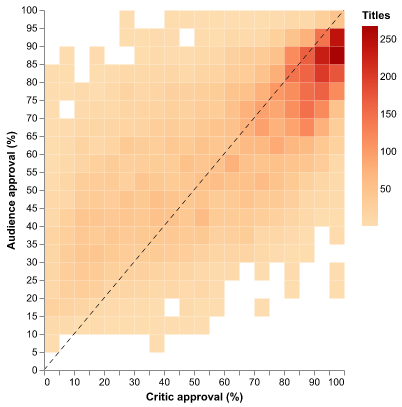

In [4]:
q1 = summary(base)
display(q1.round(3).rename("value").to_frame())
verdicts = (
    base.verdict.value_counts()
    .reindex(GROUPS, fill_value=0)
    .rename_axis("verdict")
    .reset_index(name="titles")
)
verdicts["percent"] = (100 * verdicts.titles / len(base)).round(2)
display(verdicts)
score_chart(base)


### Interpretation

About 22% of the 10,503 titles fall on opposite sides of 60%. The signed mean gap is only +0.29 points, but the mean absolute gap is 15.19 points, and 29.75% of titles are at least 20 points apart. Positive and negative differences cancel in the signed average. The correlation of 0.70 shows that the scores tend to move together, even when individual gaps are large.

## Question 2: Does the direction of the gap vary across genres?

I compare genres with at least 100 qualifying titles. Positive gaps mean higher audience approval, and negative gaps mean higher critic approval. A movie with several labels enters each relevant genre group, so these groups overlap.

,genre,titles,mean_gap_pp,median_gap_pp,mean_absolute_gap_pp,opposite_sides_pct
7,Documentary,1040,-8.21,-8.0,12.56,11.73
17,Special Interest,689,-6.50,-8.0,12.34,13.06
4,Classics,637,-5.93,-7.0,10.15,6.59
3,Art House & International,1428,-5.23,-6.5,13.46,19.68
11,Horror,1062,-3.43,-5.0,16.25,25.05
20,Western,126,-1.68,-2.5,12.38,13.49
14,Mystery & Suspense,2189,-0.36,-2.0,15.22,21.15
8,Drama,5898,-0.02,-2.0,14.94,23.55
13,Musical & Performing Arts,543,0.30,-3.0,12.51,16.94
1,Animation,399,0.32,-2.0,12.92,16.79


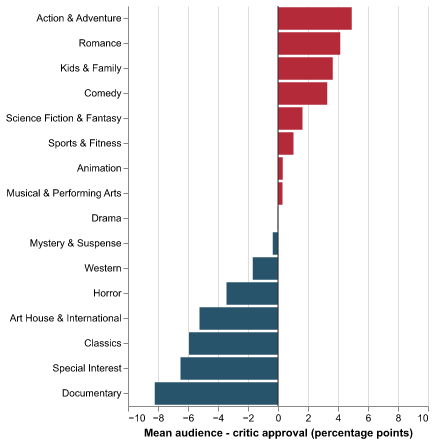

In [5]:
q2 = genre_summary(base, min_titles=100)
display(q2.round(2))
genre_chart(q2)


### Genre interpretation and the median check

Action & Adventure has a mean gap of +4.92 points across 2,204 titles. Documentary has −8.21 across 1,040. Their medians are +3 and −8, so both summaries point in the same direction for these examples.

The mean averages all title gaps. The median takes the middle sorted gap, averaging the middle two for an even count. Large gaps can pull the mean more than the median, which is why I check both.

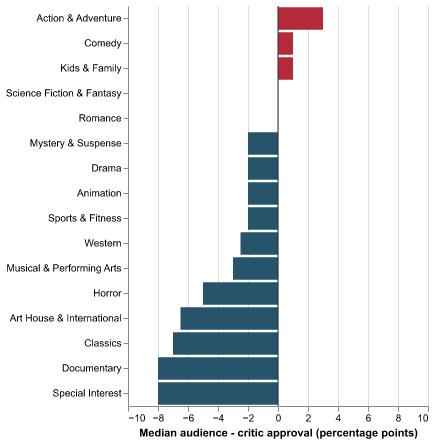

In [6]:
genre_chart(q2, statistic="median_gap_pp")


## Check 1: Do the genre findings survive stricter filters?

I compare the default **20/100** minimums with **50/1,000**. The scores stay unchanged, but fewer titles qualify under the stricter rule.

Red circles show the default means and teal diamonds show the stricter means. The table includes both sample sizes, means and medians. B − A is the difference between the means. Genres need at least 100 titles in both samples to appear in the chart.

The comparison labels use the means. A value within ±1 point is labelled near zero. “Too few titles” means either sample is below the genre minimum. These are descriptive labels, not significance tests.

,genre,titles_A,mean_gap_pp_A,median_gap_pp_A,titles_B,mean_gap_pp_B,median_gap_pp_B,enough_titles,change_pp,direction
0,Action & Adventure,2204,4.92,3.0,1408,6.85,5.0,True,1.93,Audience higher in both
1,Animation,399,0.32,-2.0,299,0.15,-3.0,True,-0.17,Near zero in at least one view
2,Anime & Manga,11,8.45,-4.0,2,4.50,4.5,False,-3.95,Too few titles
3,Art House & International,1428,-5.23,-6.5,633,-5.06,-7.0,True,0.17,Critics higher in both
4,Classics,637,-5.93,-7.0,149,-2.54,-5.0,True,3.40,Critics higher in both
5,Comedy,3514,3.28,1.0,2039,4.21,1.0,True,0.93,Audience higher in both
6,Cult Movies,49,-6.78,-7.0,17,-3.82,-8.0,False,2.95,Too few titles
7,Documentary,1040,-8.21,-8.0,357,-7.31,-8.0,True,0.91,Critics higher in both
8,Drama,5898,-0.02,-2.0,3235,1.68,-1.0,True,1.69,Near zero in at least one view
9,Faith & Spirituality,43,8.07,1.0,10,8.30,4.5,False,0.23,Too few titles


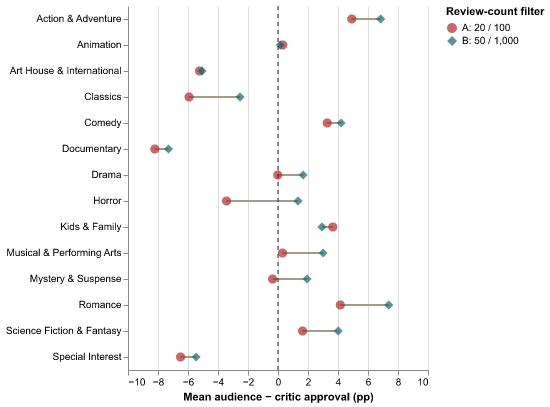

In [7]:
comparison = compare_profiles(movies, (20, 100), (50, 1000), min_titles=100)
display(comparison.round(2))
comparison_chart(comparison[comparison.enough_titles], "A: 20 / 100", "B: 50 / 1,000")


### What changes?

Horror’s mean moves from −3.43 across 1,062 titles to +1.33 across 553. Its median stays negative, moving from −5 to −1. A claim based only on the mean would miss that difference. Action & Adventure stays audience-higher (+4.92 to +6.85), while Documentary stays critic-higher (−8.21 to −7.31).

Animation changes much less: its mean moves from +0.32 across 399 titles to +0.15 across 299, with medians of −2 and −3. The two examples show why it helps to check the sample and the summary before making a broad genre claim.

In [8]:
profile_results = []
for label, (critics, audience) in PROFILES.items():
    selected = filter_movies(movies, critics, audience)
    profile_results.append({"filter": label, **summary(selected).to_dict()})
display(pd.DataFrame(profile_results).round(3))


,filter,titles,opposite_sides_pct,mean_absolute_gap_pp,mean_gap_pp,median_gap_pp,gap_at_least_20_pct,pearson_r
0,Broad · 10 / 50,13967.0,23.169,15.954,0.060,-2.0,31.975,0.680
1,Default · 20 / 100,10503.0,22.013,15.191,0.293,-2.0,29.753,0.702
2,Stricter · 50 / 500,5882.0,21.268,14.823,2.012,-1.0,28.613,0.716
3,"Strict · 50 / 1,000",5734.0,21.015,14.745,2.366,-1.0,28.305,0.722
4,"Very strict · 100 / 1,000",3336.0,21.523,14.386,2.242,0.0,27.188,0.710


## Check 2: Does the release-period mix matter?

I group titles by release year: before 1980, 1980–1999, 2000–2009 and 2010–2020. The periods span different numbers of years. Titles with missing years are excluded here, and the heatmap hides genre-period groups with fewer than 20 titles. A blank cell does not mean a zero gap.

Excluded from release-period analysis:  226 titles without a release year


,period,titles,opposite_sides_pct,mean_absolute_gap_pp,mean_gap_pp,median_gap_pp,gap_at_least_20_pct,pearson_r
0,Before 1980,932.0,6.652,9.656,-6.518,-7.0,10.944,0.757
1,1980–1999,1979.0,20.465,13.932,3.916,2.0,25.114,0.758
2,2000–2009,3173.0,23.731,16.022,6.513,4.0,32.461,0.692
3,2010–2020,4193.0,24.589,16.273,-4.218,-7.0,33.627,0.671


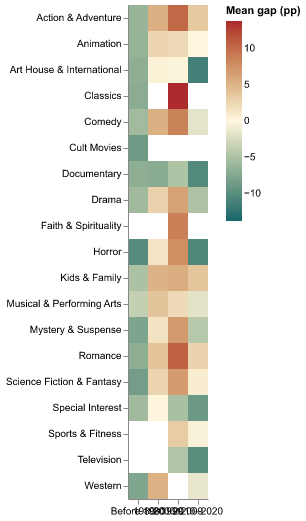

In [9]:
periods = period_summary(base)
print(
    "Excluded from release-period analysis: ",
    base.release_year.isna().sum(),
    "titles without a release year",
)
display(periods.round(3))
cells = period_genres(base)
period_chart(cells, min_titles=20)


### What does the period comparison show?

The mean gaps are −6.52, +3.92, +6.51 and −4.22 points, with 932, 1,979, 3,173 and 4,193 titles respectively. Another 226 titles have no release year. Since the means differ across periods, a genre’s mix of older and newer titles could affect its overall average.

## Give genres the same release-period mix

I recalculate each genre’s mean using the same period weights: the shares of all known-year titles in the default sample. Only genres with at least 20 titles in every represented period qualify. The observed comparison also excludes unknown-year titles, so both means use the same titles.

In [10]:
standardized, weights = standardized_genres(base, min_per_period=20)
display((weights * 100).rename("Reference share (%)").to_frame().round(3))
display(standardized.round(3))


,Reference share (%)
release_period,
Before 1980,9.069
1980–1999,19.257
2000–2009,30.875
2010–2020,40.8


,genre,titles,observed_gap_pp,same_period_mix_gap_pp,change_pp,periods
4,Documentary,1014,-8.119,-7.743,0.376,4
12,Special Interest,680,-6.440,-5.690,0.750,4
2,Art House & International,1400,-5.121,-5.204,-0.082,4
6,Horror,1032,-3.070,-2.607,0.463,4
9,Mystery & Suspense,2137,-0.107,-0.055,0.052,4
5,Drama,5791,0.084,-0.007,-0.091,4
8,Musical & Performing Arts,532,0.320,0.348,0.028,4
1,Animation,392,0.740,0.640,-0.100,4
11,Science Fiction & Fantasy,1199,1.763,2.173,0.410,4
3,Comedy,3448,3.364,2.441,-0.923,4


### What changes with common weights?

Comedy’s mean decreases from +3.36 to +2.44 points. Action & Adventure stays near +5, and Documentary stays negative (−8.12 to −7.74). Animation changes little, from +0.74 to +0.64 across 392 known-year titles. These examples keep their direction under this particular check.

## Saved data and reproducibility

`python scripts/prepare_data.py` saves all 17,712 source titles in `data/processed/movie_scores.csv`, with eligibility flags and a preparation record. The raw file stays unchanged. The app reads the processed table.

`python scripts/check_project.py` checks the data and calculations. `python scripts/check_app.py` exercises the app controls and CSV exports. The README gives the setup and data-access steps.

In [11]:
metadata, prepared = load_prepared()
assert len(prepared) == len(raw)
assert prepared.rotten_tomatoes_link.is_unique
pd.testing.assert_series_equal(
    filter_movies(prepared).gap_pp, base.gap_pp, check_names=True
)
print(
    "Prepared rows:",
    len(prepared),
    "| Comparison-eligible rows:",
    metadata["comparison_eligible"],
)
print("Raw SHA256:", metadata["raw_sha256"])
print("Processed SHA256:", metadata["processed_sha256"])


Prepared rows: 17712 | Comparison-eligible rows: 17406
Raw SHA256: c21dbd4849691e9b938a1bba362e374bb1aa82d5178ce7b8e06a17c14c3e9251
Processed SHA256: b369fdfdd0e2303ac048bf405c9c2db00e0f5b7fc37912a25e9b6c2e2e2b0290


## Conclusions and limitations

The overall averages hide sizable differences between individual titles. Genre averages add detail, but the Horror example shows that the conclusion can depend on the sample and on whether I use the mean or median.

These are approval percentages rather than average stars, and critics and audiences use different scoring rules. The selected 2020 catalog cannot tell us about current opinions or explain why people disagree. Genre groups overlap, and the release-year comparisons do not track changing opinions over time. Count minimums and the near-zero tolerance are analysis choices. Common period weights check one source of compositional difference without establishing causes.

The questions are descriptive, so I do not need imputation, scaling, categorical encoding or a predictive model.

**AI assistance**: I used OpenAI Codex (GPT-6.1) to help implement and refine the app, including the Streamlit UI, tests, deployment setup, and documentation drafts. I chose the project direction, reviewed the work and took responsibility for the analysis, interpretation, graphs and final conclusions.